<a href="https://colab.research.google.com/github/N3H4-Singh/AI-Engineer-Journey/blob/main/Machine-Learning/Logistic-Regression/Logistic_Regression_Customer_Churn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer Churn Prediction Using Logistic Regression

## Project Objective

The objective of this project is to develop a Machine Learning classification model using Logistic Regression to predict whether a telecommunications customer is likely to leave the company (churn) or continue using its services.

The project involves:
- Understanding and exploring customer data.
- Identifying missing values and duplicate records.
- Handling categorical and numerical features.
- Encoding categorical variables.
- Splitting the dataset into training and testing sets.
- Training a Logistic Regression model.
- Predicting customer churn.
- Evaluating the model using Accuracy, Precision, Recall, F1-score, and Confusion Matrix.
- Visualizing model performance.

In [2]:
import pandas as pd
import numpy as np
df = pd.read_csv('/content/WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [3]:
df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


In [10]:
df['Churn'].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.463013
Yes,26.536987


In [11]:
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)
df['TotalCharges'].isnull().sum()

np.int64(11)

In [12]:
df['TotalCharges'] = df['TotalCharges'].fillna(
    df['TotalCharges'].mean()
)
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [13]:
df.drop('customerID', axis=1, inplace= True)

In [14]:
df['Churn'] = df['Churn'].map({
    'Yes' : 1, 'No' : 0
})

In [15]:
df['Churn'].value_counts()

,count
Churn,
0,5174
1,1869


In [16]:
categorical_cols = df.select_dtypes(
    include = 'object'
).columns

print(categorical_cols)

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object')


In [17]:
df = pd.get_dummies(
    df,
    columns = categorical_cols,
    dtype = int
)

In [18]:
df.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,1,...,0,1,0,0,0,1,0,0,1,0
1,0,34,56.95,1889.50,0,0,1,1,0,1,...,0,0,1,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,1,1,0,1,...,0,1,0,0,0,1,0,0,0,1
3,0,45,42.30,1840.75,0,0,1,1,0,1,...,0,0,1,0,1,0,1,0,0,0
4,0,2,70.70,151.65,1,1,0,1,0,1,...,0,1,0,0,0,1,0,0,1,0


In [19]:
df.shape

(7043, 46)

In [20]:
X = df.drop('Churn', axis=1)
y = df['Churn']

In [21]:
print("Features Shape: ", X.shape)
print("Target Shape: ", y.shape)

Features Shape:  (7043, 45)
Target Shape:  (7043,)


In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [23]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 45)
Testing data: (1409, 45)


In [24]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [25]:
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Training shape: (5634, 45)
Testing shape: (1409, 45)


In [26]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter = 1000)

model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [27]:
y_pred = model.predict(X_test_scaled)
print(y_pred[:5])

[0 1 0 0 0]


In [28]:
comparison = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})
print(comparison.head(10))

      Actual  Predicted
437        0          0
2280       0          1
2235       0          0
4460       0          0
3761       0          0
5748       0          1
3568       0          0
2976       0          0
5928       0          0
1639       1          0


In [29]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.8069552874378992


In [30]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.57      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



[[925 110]
 [162 212]]


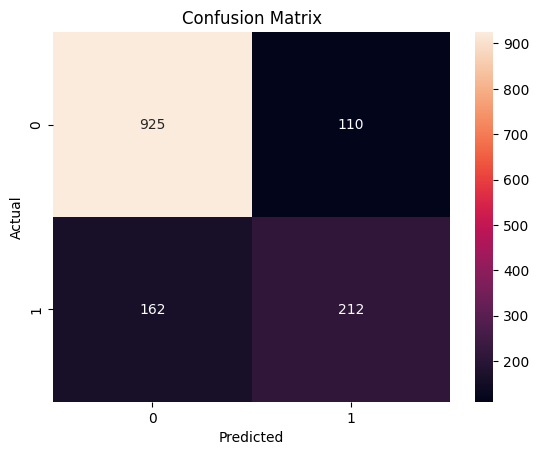

In [31]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print(cm)

sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

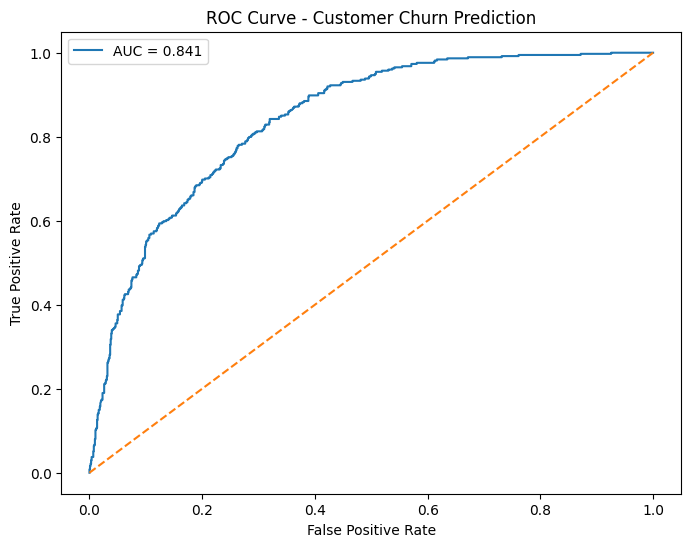

AUC Score: 0.8414761424991605


In [32]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_prob = model.predict_proba(X_test_scaled)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'AUC = {auc_score:.3f}')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Customer Churn Prediction")
plt.legend()
plt.show()

print("AUC Score:", auc_score)

In [35]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.57      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [36]:
# Get churn probabilities
y_prob = model.predict_proba(X_test_scaled)[:, 1]

# Change threshold from 0.5 to 0.4
y_pred_04 = (y_prob >= 0.4).astype(int)

# Evaluate new predictions
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_04))

              precision    recall  f1-score   support

           0       0.87      0.82      0.84      1035
           1       0.57      0.67      0.61       374

    accuracy                           0.78      1409
   macro avg       0.72      0.74      0.73      1409
weighted avg       0.79      0.78      0.78      1409



In [37]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("THRESHOLD 0.5")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nTHRESHOLD 0.4")
print("Accuracy:", accuracy_score(y_test, y_pred_04))
print("Precision:", precision_score(y_test, y_pred_04))
print("Recall:", recall_score(y_test, y_pred_04))
print("F1 Score:", f1_score(y_test, y_pred_04))

THRESHOLD 0.5
Accuracy: 0.8069552874378992
Precision: 0.6583850931677019
Recall: 0.5668449197860963
F1 Score: 0.6091954022988506

THRESHOLD 0.4
Accuracy: 0.7764371894960965
Precision: 0.5668934240362812
Recall: 0.6684491978609626
F1 Score: 0.6134969325153374


## Conclusion

In this project, I developed a Customer Churn Prediction model using Logistic Regression and the Telco Customer Churn dataset.

The workflow included:
- Data exploration and cleaning
- Handling missing values
- Encoding categorical variables
- Train-test splitting
- Feature scaling using StandardScaler
- Model training and prediction
- Evaluation using Accuracy, Precision, Recall, F1-score, Confusion Matrix and ROC-AUC

### Model Performance

- Accuracy: 81%
- ROC-AUC: 0.84
- Precision (Churn): 66%
- Recall (Churn): 57%
- F1-score (Churn): 0.61

### Key Learning

The model performs better at identifying customers who stay than customers who churn. The 57% churn recall indicates that there is room to improve the identification of at-risk customers.

This project helped me understand classification algorithms, model evaluation metrics and the importance of selecting appropriate evaluation metrics for business problems.